# Stock Buy Decision

**Nhánh C từ 2026-07-17 (SDE_SCORING_REPORT.md, Vòng 3)**: đây là bảng dữ
kiện tham khảo, KHÔNG còn điểm tổng hợp hay khuyến nghị mua/bán -- IC
Newey-West và null-test đều không đạt tiêu chí đã khóa trước cho
`final_score` lẫn từng sub-score. Đọc `stock-decision-engine/SDE_SCORING_REPORT.md`
trước khi dùng bất kỳ số nào dưới đây.

In [1]:
TICKER = "tcb"
BENCHMARK = "VNINDEX"
CONFIG_PATH = "../config.yaml"

In [2]:
from pathlib import Path
import sys

NOTEBOOK_DIR = Path.cwd()
ENGINE_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else Path("stock-decision-engine").resolve()
PROJECT_ROOT = ENGINE_ROOT.parent
SRC = ENGINE_ROOT / "src"
for p in [str(SRC), str(PROJECT_ROOT)]:
    if p not in sys.path:
        sys.path.insert(0, p)

from data import load_config, load_stock_ohlcv, load_benchmark_ohlcv, load_backtest_evidence
from features import enrich
from simulation import bootstrap_monte_carlo
from scoring import build_facts_table
from report import facts_summary, save_outputs
from visualization import save_all_charts

## Load Data

In [3]:
cfg_path = (ENGINE_ROOT / "notebooks" / CONFIG_PATH).resolve()
cfg = load_config(cfg_path, PROJECT_ROOT)
cfg["ticker"] = TICKER
cfg["benchmark"] = BENCHMARK

stock = load_stock_ohlcv(TICKER, PROJECT_ROOT, cfg["lookback_days"])
benchmark = load_benchmark_ohlcv(BENCHMARK, PROJECT_ROOT, cfg["lookback_days"])
backtest = load_backtest_evidence(TICKER, PROJECT_ROOT)

print(f"Loaded {len(stock):,} stock rows and {len(benchmark):,} benchmark rows.")

Loaded 756 stock rows and 756 benchmark rows.


## Features, Simulation, Score

In [4]:
stock_f, benchmark_f, relative_strength, rolling_alpha_beta, metrics = enrich(stock, benchmark, cfg)
mc = bootstrap_monte_carlo(stock_f, metrics, cfg)
facts = build_facts_table(metrics, mc.summary, backtest, cfg)

facts["facts"]

/opt/anaconda3/envs/vnquant/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:377: RuntimeWarning: invalid value encountered in cast
  new_result = trans(result).astype(dtype)
/opt/anaconda3/envs/vnquant/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:377: RuntimeWarning: invalid value encountered in cast
  new_result = trans(result).astype(dtype)


,component,reading,reason
0,market_regime,40.0,"Benchmark trend, slope, returns, drawdown, and..."
1,trend,20.0,"MA structure, slopes, ADX/+DI, and breakout co..."
2,momentum,29.0,"Multi-horizon returns, RSI, MACD, and accelera..."
3,relative_strength,75.0,"Excess return, RS slope, beta, and correlation."
4,alpha,90.0,"CAPM alpha, Sharpe/Sortino/IR/Calmar, and opti..."
5,risk,80.0,"ATR, volatility percentile, drawdown, CVaR, sk..."
6,liquidity,93.0,"Average value, volume participation, z-score, ..."
7,simulation,48.0,"Bootstrap probability, expected return, and si..."


## Dashboard Charts

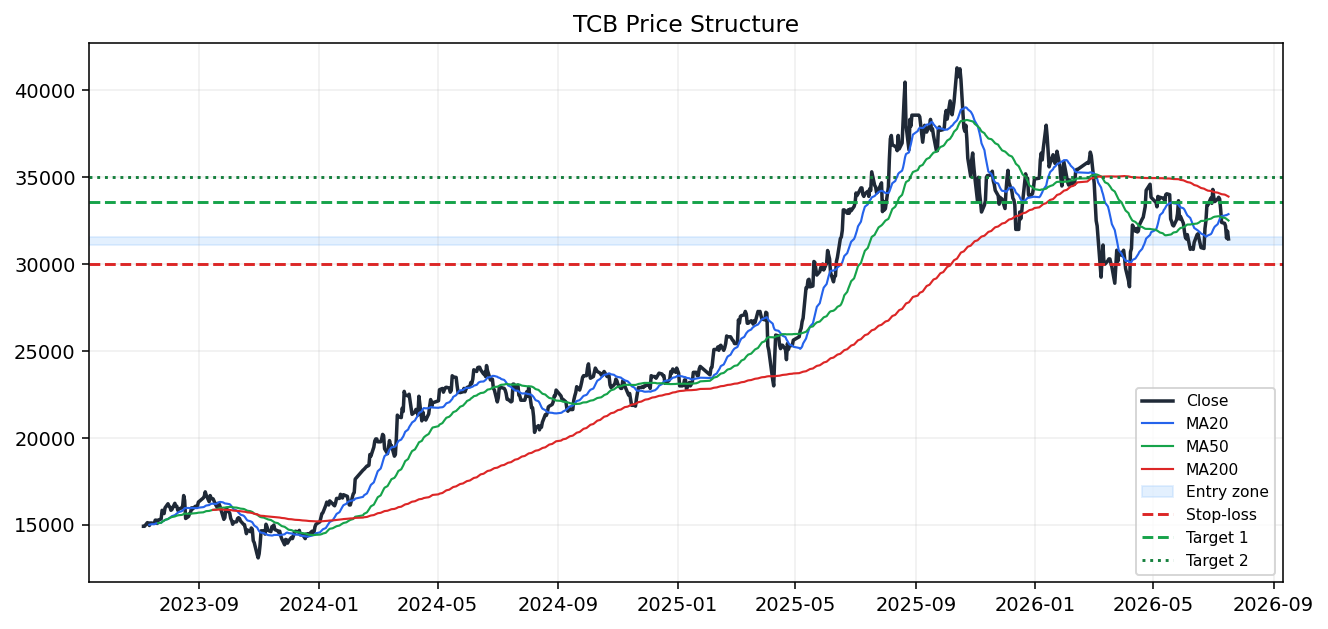

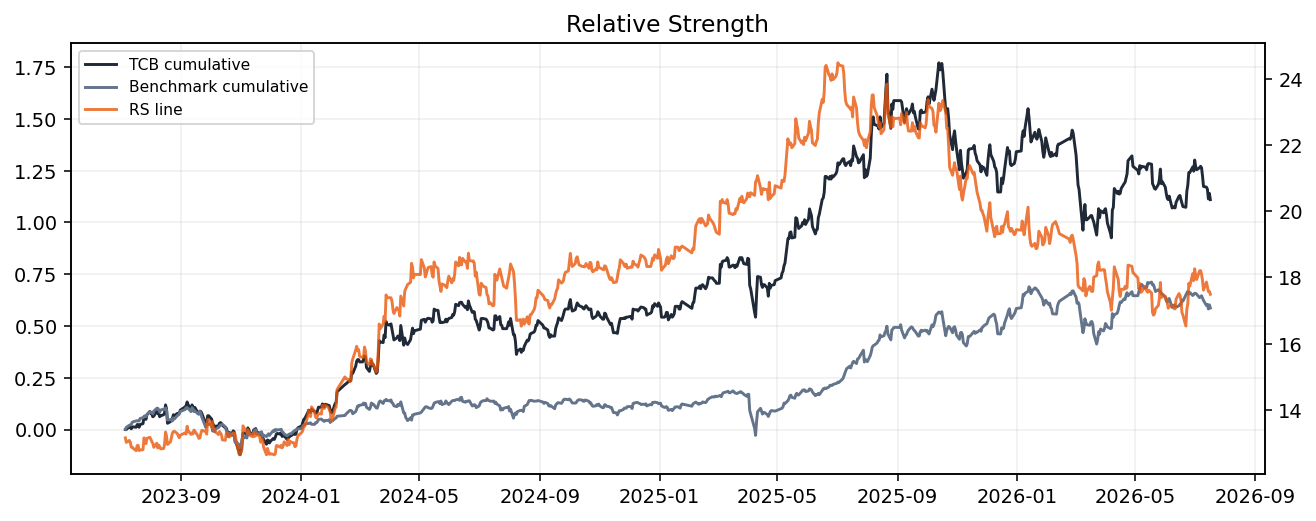

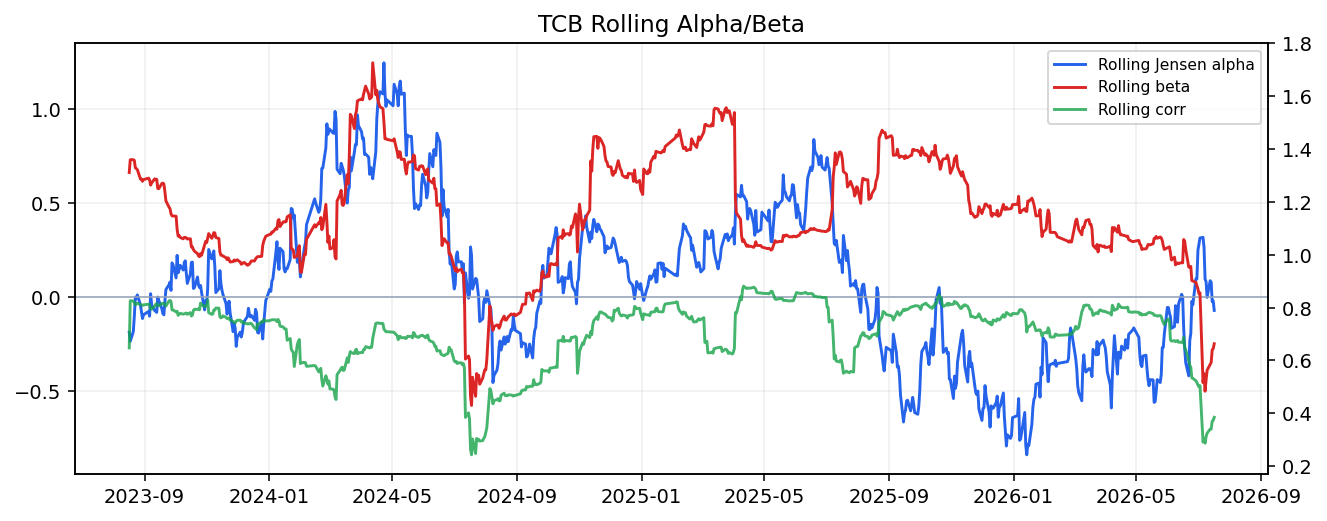

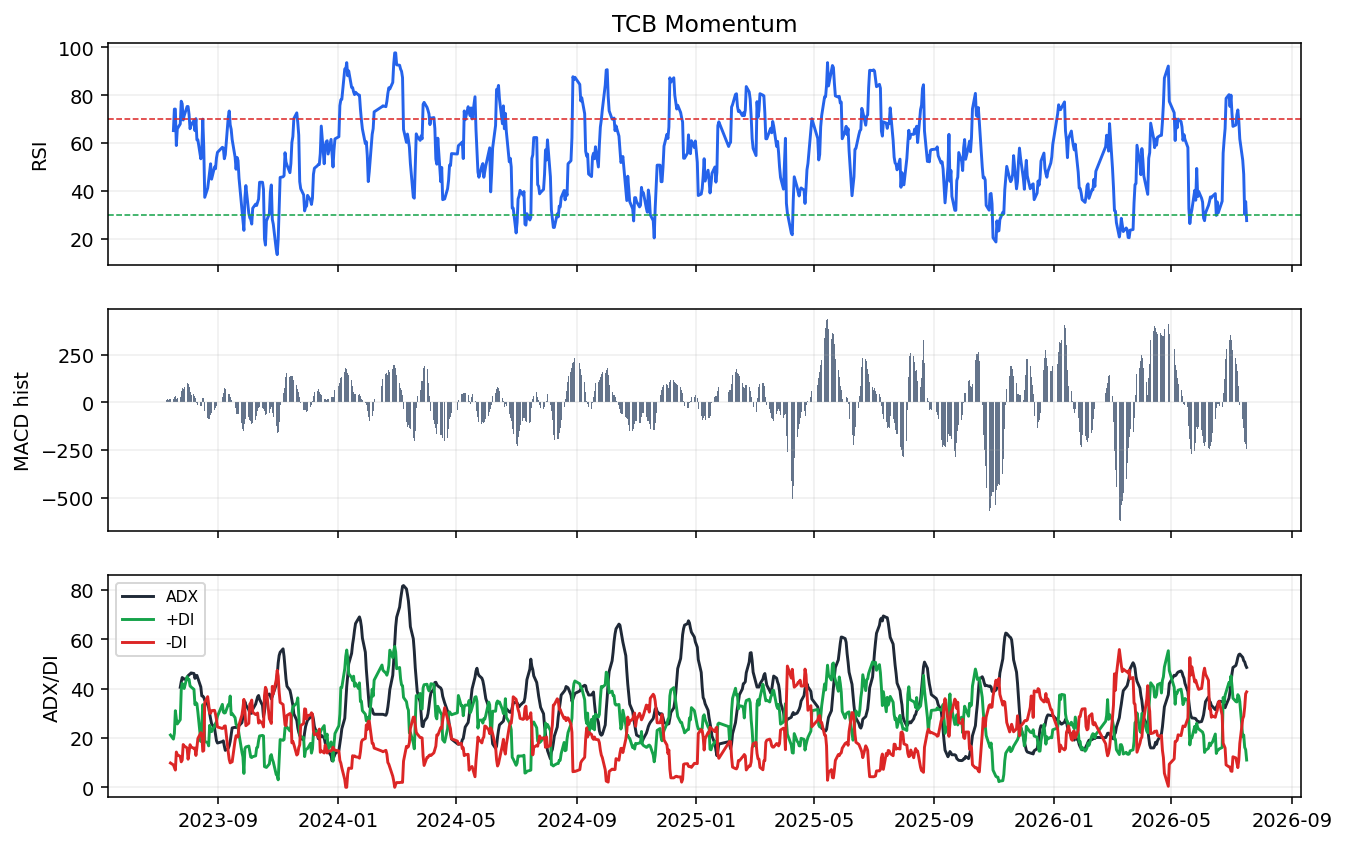

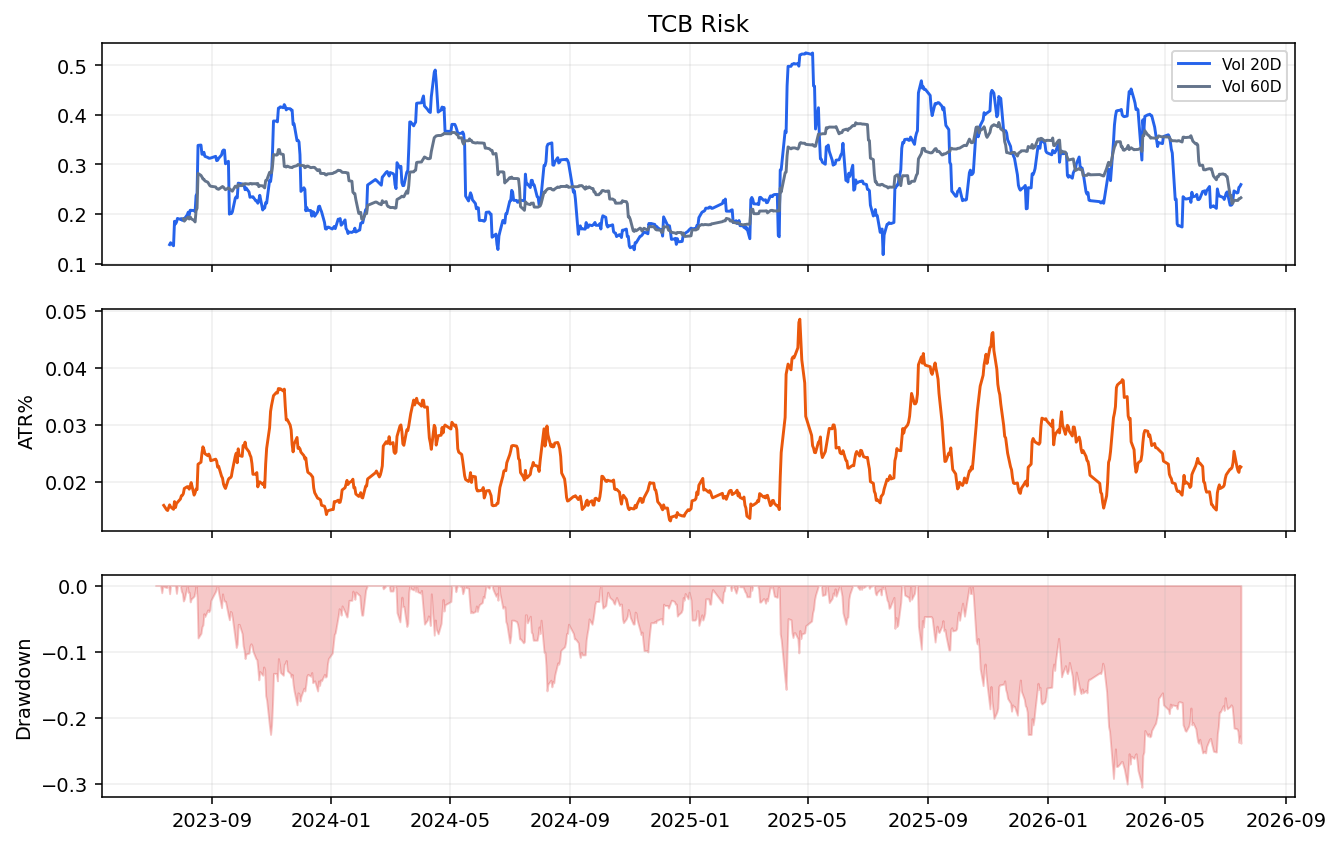

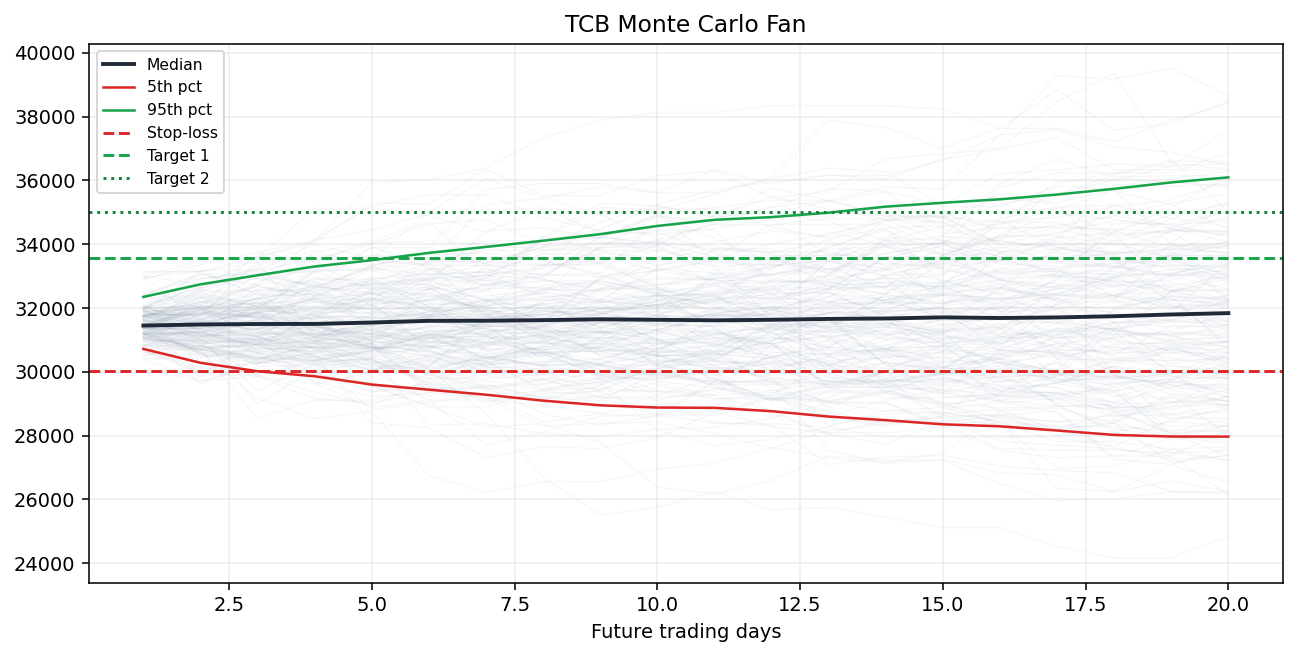

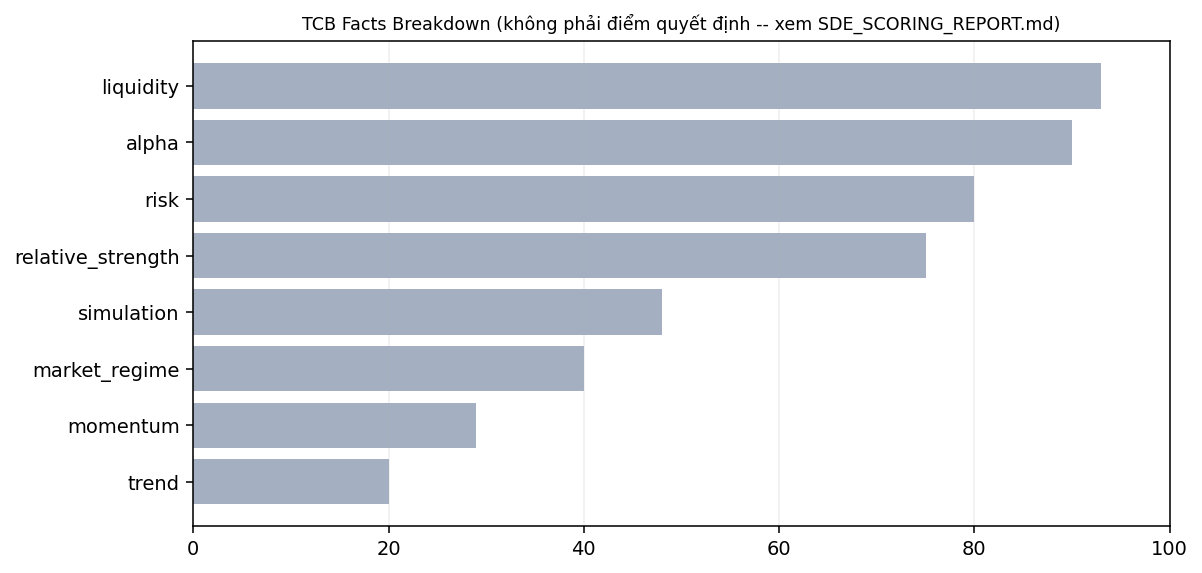

{'price_structure': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/TCB_price_structure.png'),
 'relative_strength': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/TCB_relative_strength.png'),
 'rolling_alpha_beta': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/TCB_rolling_alpha_beta.png'),
 'momentum': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/TCB_momentum.png'),
 'risk': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/TCB_risk.png'),
 'monte_carlo_fan': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/TCB_monte_carlo_fan.png'),
 'facts_breakdown': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/TCB_facts_breakdown.png')}

In [5]:
outputs_dir = ENGINE_ROOT / "outputs"
from IPython.display import Image, display

chart_paths = save_all_charts(
    stock_f,
    benchmark_f,
    relative_strength,
    rolling_alpha_beta,
    mc.paths,
    metrics,
    facts,
    outputs_dir,
    TICKER,
)
for path in chart_paths.values():
    display(Image(filename=str(path)))
chart_paths

## Facts Summary (không phải khuyến nghị -- xem SDE_SCORING_REPORT.md)

In [6]:
saved = save_outputs(outputs_dir, TICKER, metrics, facts, mc.summary, backtest, root=PROJECT_ROOT)
summary = facts_summary(TICKER, metrics, facts, mc.summary)
print(summary)
saved

Ticker: TCB
Date: 2026-07-17

*** BẢNG DỮ KIỆN THAM KHẢO -- KHÔNG PHẢI KHUYẾN NGHỊ MUA/BÁN ***
Không có điểm tổng hợp hay xếp loại quyết định nào ở đây. Vòng 3
(SDE_SCORING_REPORT.md) xác nhận final_score/decision cũ không có
bằng chứng dự báo (IC Newey-West và null-test đều không đạt tiêu
chí đã khóa trước) -- công thức đã gỡ bỏ hoàn toàn, không chỉ ẩn.

ATR-based reference levels (không phải điểm vào lệnh khuyến nghị):
  Entry zone: 31,095 - 31,539
  Stop-loss:  30,029
  Target 1:   33,582
  Target 2:   35,004
  Risk/Reward: 1.50

Market Regime: Weak
Trend: Downtrend
Momentum: Weak
Relative Strength: Outperforming
Alpha (CAPM): 9.98%
Risk: Controlled
Liquidity: Passed
Simulation: 34.8% target-before-stop probability

Chi tiết theo nhóm (reading 0-100 = số tiêu chí TA nội bộ đạt,
KHÔNG phải xác suất/điểm dự báo -- không có nhóm nào ở đây đã qua
kiểm định IC/null-test):
  - market_regime: 40/100 - Benchmark trend, slope, returns, drawdown, and volatility.
  - trend: 20/100 - MA structu

{'summary': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/TCB_2026-07-17_facts_summary.txt'),
 'facts': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/TCB_2026-07-17_facts.csv'),
 'metrics': PosixPath('/Users/jamesb/Desktop/vietnam-quant-research/stock-decision-engine/outputs/TCB_2026-07-17_metrics.csv')}